
FIT 1

###
A = 1.374e+04 ± 9.527
B = 2.139 ± 0.03742
C = 0.001869 ± 8.28e-05
###
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1107                       │              Nfcn = 220              │
│ EDM = 3.99e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─

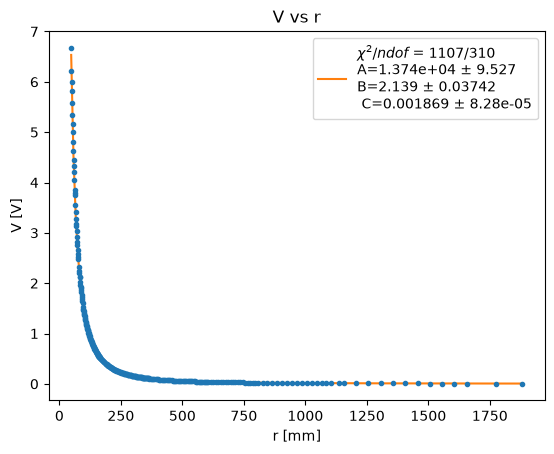

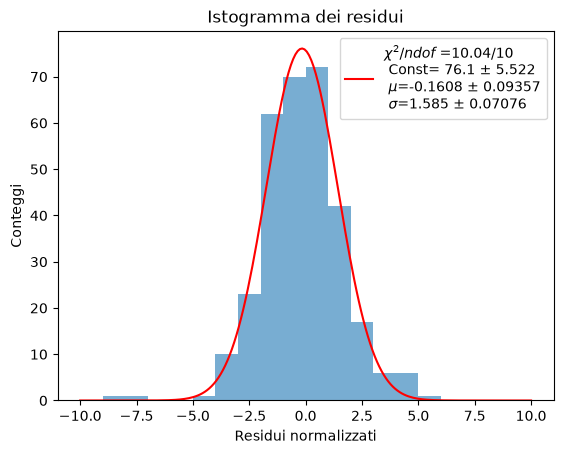

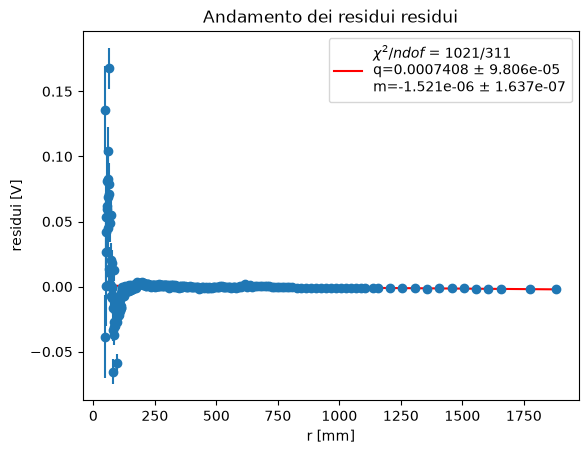

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from iminuit import Minuit

dati = np.loadtxt("dati_Sensibilita.txt", skiprows=1) 
x = dati[:,0]
y = dati[:,1]
ex = dati[:,3]
ey = dati[:,2]

def fitfunc(x, A , B, C):
    return (A / (x-B)**2) + C

def fitfuncprime(x, A, B, C):
    dx = 1e-6
    return (fitfunc(x+dx/2, A, B, C)-fitfunc(x-dx/2, A, B, C))/dx

def chi2_fitfunc(A, B, C):
    sigma = np.sqrt(ey**2 + (ex * fitfuncprime(x, A, B, C))**2)
    return np.sum(((y - fitfunc(x, A, B, C)) / sigma)**2)

print("")
print("FIT 1")
print("")

m = Minuit(chi2_fitfunc, B= 1.804 , C= 0.0004456, A= 1.385e+04 ) # mettere b posz lampada e A calcola
m.migrad()
m.hesse()
m.minos()

A_fit = m.values["A"]
B_fit = m.values["B"]
C_fit = m.values["C"]



A_err = m.errors["A"]
B_err = m.errors["B"]
C_err = m.errors["C"]

print("###")
print(f"A = {A_fit:5.4g} ± {A_err:5.4g}")
print(f"B = {B_fit:5.4g} ± {B_err:5.4g}")
print(f"C = {C_fit:5.4g} ± {C_err:5.4g}")
print("###")
print(m)
print("###")

x_fit = np.linspace(min(x), max(x), 200)
y_fit = fitfunc(x_fit, A_fit, B_fit, C_fit)

plt.errorbar(x, y, xerr=ex, yerr=ey, fmt='.')
plt.plot(x_fit, y_fit, label=f"$\\chi^2/ndof$ ={chi2_fitfunc(A_fit, B_fit, C_fit):5.4g}/{len(x)-3}\nA={A_fit:5.4g} $\\pm$ {A_err:5.4g}\nB={B_fit:5.4g} $\\pm$ {B_err:5.4g} \n C={C_fit:5.4g} $\\pm$ {C_err:5.4g}")

plt.title(f'V vs r')
plt.xlabel('r [mm]')
plt.ylabel('V [V]')
plt.legend()
plt.savefig("FIT1.pdf")
#plt.show()

# ---- residui ----

y_res = y - fitfunc(x, A_fit, B_fit, C_fit)
ey_eff = np.sqrt(ey**2 + (ex * fitfuncprime(x, A_fit, B_fit, C_fit))**2)


print("")
print("FIT 2")
print("")

plt.figure()
counts, bins, _ = plt.hist(y_res / ey_eff, range=(-10,10), bins=20, alpha=0.6)

def gauss(x, par0, par1, par2):
    return par0 * np.exp(-0.5 * np.power((x - par1) / par2, 2.0))

def chi2_gauss(par0, par1, par2):
    mask = counts>0
    return np.sum(((counts[mask] - gauss((bins[:-1] + bins[1:])[mask]/2, par0, par1, par2)) / np.sqrt(counts[mask]))**2)

m = Minuit(chi2_gauss, par0=1.0, par1=0.0, par2=1.0)
m.migrad()
m.hesse()
m.minos()

Constant_fit = m.values["par0"]
Mean_fit = m.values["par1"]
Sigma_fit = m.values["par2"]

Constant_err = m.errors["par0"]
Mean_err = m.errors["par1"]
Sigma_err = m.errors["par2"]

print("###")
print(f"Const = {Constant_fit:5.4g} ± {Constant_err:5.4g}")
print(r"$\mu$" + f"= {Mean_fit:5.4g} ± {Mean_err:5.4g}")
print(r"$\sigma$" + f"= {Sigma_fit:5.4g} ± {Sigma_err:5.4g}")
print("###")
print(m)
print("###")

x_fit = np.linspace(-10, 10, 200)
y_fit = gauss(x_fit, Constant_fit, Mean_fit, Sigma_fit)

plt.plot(x_fit, y_fit, 'r-', label=f"$\\chi^2/ndof$ ={chi2_gauss(Constant_fit, Mean_fit, Sigma_fit):5.4g}/{np.count_nonzero(counts)-3}\n Const={Constant_fit:5.4g} $\\pm$ {Constant_err:5.4g}\n " + r"$\mu$" +f"={Mean_fit:5.4g} $\\pm$ {Mean_err:5.4g}\n " + r"$\sigma$" +f"={Sigma_fit:5.4g} $\\pm$ {Sigma_err:5.4g}")

plt.title(f"Istogramma dei residui")
plt.xlabel("Residui normalizzati")
plt.ylabel("Conteggi")
plt.legend()
plt.savefig("Grafico_residui_1_FIT.pdf")
#plt.show()


print("")
print("FIT 3")
print("")

plt.figure()
plt.errorbar(x, y_res, yerr=ey_eff, fmt='o')

def retta(x, par0, par1):
    return par0 + par1 * x

def chi2_retta(par0, par1):
    sigma = ey_eff
    return np.sum(((y_res - retta(x, par0, par1)) / ey_eff)**2)

m = Minuit(chi2_retta, par0=0.0, par1=0.0)
m.migrad()
m.hesse()
m.minos()



q_fit = m.values["par0"]
m_fit = m.values["par1"]

q_err = m.errors["par0"]
m_err = m.errors["par1"]

print("###")
print(f"q = {q_fit:5.4g} ± {q_err:5.4g}")
print(f"m = {m_fit:5.4g} ± {m_err:5.4g}")
print("###")
print(m)
print("###")

x_fit = np.linspace(min(x), max(x), 200)
y_fit = retta(x_fit, q_fit, m_fit)

plt.plot(x_fit, y_fit, 'r-', label=f"$\\chi^2/ndof$ ={chi2_retta(q_fit, m_fit):5.4g}/{len(x)-2}\nq={q_fit:5.4g} $\\pm$ {q_err:5.4g}\nm={m_fit:5.4g} $\\pm$ {m_err:5.4g}")

#plt.ylim(-2.0, +2.0)

plt.title(f"Andamento dei residui residui")
plt.xlabel("r [mm]")
plt.ylabel("residui [V]")
plt.legend()
plt.savefig("Grafico_compatibilita_residui.pdf")
#plt.show()

###

plt.show()

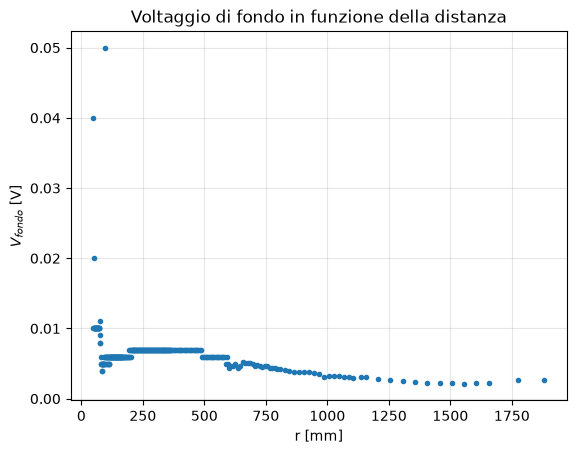

il fotodiodo stava inizialmente vicino all'armadio, mnagari è per questo che è alto all'inizio?


In [4]:
# faccio un grafico dove connfronto il voltaggio di fondo con r per vedere se è stabile
y_fondo = dati[:,4]
plt.plot(x, y_fondo, '.')
plt.xlabel('r [mm]')
plt.ylabel(r'$V_{fondo}$ [V]')
plt.title('Voltaggio di fondo in funzione della distanza')
plt.grid(True, alpha=0.3)
plt.savefig("Grafico_V_fondo_vs_r.pdf", bbox_inches="tight")
plt.show()

print("il fotodiodo stava inizialmente vicino all'armadio, mnagari è per questo che è alto all'inizio?")

In [5]:
print("faccio un secondo fit supponendo una seconda sorgente alla stessa altezza ")
print("lo faccio per capire se c'è una seconda sorgente che influenza il primo fit")
print()
print("B è la posizione della lampada")
print("B2 è la posizione della seconda sorgente nello stesso riferimento di r deve stare fuori del range di r")
print("A2 / A1 sono intensità della seconda sorgente rispetto alla lampada devono essere > 0")
print("C fondo costante rimasto per esempio luce diffusa dell’ambiente")
print("B deve essere diverso da B2 altrimenti indistinguibili e si misura la somma")
print()

def fitfunc_2(x, A, B, A2, B2, C):
    return A / (x - B)**2 + A2 / (x - B2)**2 + C

def fitfunc_2_prime(x, A, B, A2, B2, C):
    dx = 1e-6
    return (fitfunc_2(x + dx/2, A, B, A2, B2, C) - fitfunc_2(x - dx/2, A, B, A2, B2, C)) / dx

def chi2_2(A, B, A2, B2, C):
    sigma = np.sqrt(ey**2 + (ex * fitfunc_2_prime(x, A, B, A2, B2, C))**2)
    return np.sum(((y - fitfunc_2(x, A, B, A2, B2, C)) / sigma)**2)

m4 = Minuit(chi2_2, A=A_fit, B=B_fit, A2= 0.05*A_fit, B2=B_fit, C=C_fit) 
#A2 deve essere compatibile con 0 non = 0 altrimenti la derivata prima = 0


m4.errordef = 1
m4.limits["A"]  = (0, None)
m4.limits["A2"] = (0, None)
m4.limits["B"]  = (None, x.min() - 1) 
m4.limits["B2"] = (None, x.min() -1)   
# se la sorgente è dall'altra parte: (x.max() + 1, None) su b2
m4.migrad()
m4.hesse() 
print(f"chi2: {chi2_fitfunc(A_fit, B_fit, C_fit):.1f} (una sorgente) {m4.fval:.1f} (due sorgenti), se chi2 diminuisce molto allora c'è una seconda sorgente")

print(f"A={m4.values['A']:.5g} ± {m4.errors['A']:.2g}")
print(f"A2={m4.values['A2']:.5g} ± {m4.errors['A2']:.2g}")
print(f"B={m4.values['B']:.5g} ± {m4.errors['B']:.2g}")
print(f"B2={m4.values['B2']:.5g} ± {m4.errors['B2']:.2g} distanza della sorgente")
print(f"C={m4.values['C']:.5g} ± {m4.errors['C']:.2g}")

print(f"A2/A = {m4.values['A2']/m4.values['A']:.3g}, ovvero circa il {m4.values['A2']/m4.values['A']*100:.1f}% della sorgente principale")

faccio un secondo fit supponendo una seconda sorgente alla stessa altezza 
lo faccio per capire se c'è una seconda sorgente che influenza il primo fit

B è la posizione della lampada
B2 è la posizione della seconda sorgente nello stesso riferimento di r deve stare fuori del range di r
A2 / A1 sono intensità della seconda sorgente rispetto alla lampada devono essere > 0
C fondo costante rimasto per esempio luce diffusa dell’ambiente
B deve essere diverso da B2 altrimenti indistinguibili e si misura la somma

chi2: 1107.0 (una sorgente) 656.9 (due sorgenti), se chi2 diminuisce molto allora c'è una seconda sorgente
A=11688 ± 35
A2=2752.9 ± 42
B=5.1472 ± 0.054
B2=-45.231 ± 1.4 distanza della sorgente
C=0.00012992 ± 9.9e-05
A2/A = 0.236, ovvero circa il 23.6% della sorgente principale


In [6]:
residuals = y_res - fitfunc(x, A_fit, B_fit, C_fit)
residuals_mean = np.mean(residuals)
dv_std_res = np.std(residuals)
print(f"deviazione standard dei residui = {dv_std_res}")

deviazione standard dei residui = 1.2174304002276974
